# 06 - Reglas de Asociación (Algoritmo Apriori)
**Proyecto Final: Minería de Datos (Grupo 1908)**
**Objetivo:** Descubrir patrones y combinaciones de características de navegación que estén fuertemente asociadas con la realización de una compra (`Revenue = True`). Utilizaremos métricas de Soporte, Confianza y Lift.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

sns.set_style("whitegrid")

# Cargar el dataset procesado
df = pd.read_csv('../data/processed/dataset_full_encoded.csv')
print("Shape original:", df.shape)

Shape original: (12205, 59)


## 1. Discretización (Convertir números a categorías)
Apriori no entiende de números continuos (como "450.5 segundos"). Necesita categorías. Para ello, agruparemos las variables numéricas clave en **cuartiles** (Bajo, Medio, Alto, Muy Alto). 
*Ejemplo:* Si un usuario estuvo 5 segundos, será "Duración_Baja"; si estuvo 2000 segundos, será "Duración_MuyAlta".

In [2]:
# 1. Crear un nuevo DataFrame para las transacciones
df_apriori = pd.DataFrame()

# 2. Discretizar duraciones y conteos (usando qcut para cuartiles)
labels = ['Bajo', 'Medio', 'Alto', 'Muy_Alto']

# Estas variables suelen tener buena distribución para qcut
df_apriori['Duracion_Productos'] = pd.qcut(df['ProductRelated_Duration_log'], q=4, labels=labels)
df_apriori['Paginas_Productos'] = pd.qcut(df['ProductRelated'], q=4, labels=labels)

# 3. Para PageValues (muchos ceros), usamos cortes fijos (bins)
# 0 = Sin valor, luego cortes en 10, 50 y 100+
bins_pv = [-1, 0, 10, 50, df['PageValues'].max()]
labels_pv = ['Sin_Valor', 'Bajo', 'Medio', 'Alto']
df_apriori['Valor_Pagina'] = pd.cut(df['PageValues'], bins=bins_pv, labels=labels_pv)

# 4. Para BounceRates (también muchos ceros), usamos cortes fijos
bins_br = [-0.1, 0, 0.02, 0.05, 1.0]
labels_br = ['Sin_Rebote', 'Bajo', 'Medio', 'Alto']
df_apriori['Tasa_Rebote'] = pd.cut(df['BounceRates'], bins=bins_br, labels=labels_br)

# 5. Agregar variables categóricas originales
df_apriori['VisitorType'] = df['VisitorType_Returning_Visitor'].apply(lambda x: 'Returning' if x == 1 else 'New/Other')
df_apriori['Weekend'] = df['Weekend'].apply(lambda x: 'FinDeSemana' if x == 1 else 'EntreSemana')

# Para el Mes, sacamos la columna con el valor más alto (1)
df_apriori['Mes'] = df.filter(like='Month_').idxmax(axis=1).str.replace('Month_', '')

# 6. Agregar la variable objetivo (Revenue)
df_apriori['Compra'] = df['Revenue'].apply(lambda x: 'Compro' if x == 1 else 'No_Compro')

# Limpiar nulos
df_apriori = df_apriori.dropna()

print("Ejemplo de las transacciones:")
display(df_apriori.head())

Ejemplo de las transacciones:


,Duracion_Productos,Paginas_Productos,Valor_Pagina,Tasa_Rebote,VisitorType,Weekend,Mes,Compra
0,Bajo,Bajo,Sin_Valor,Alto,Returning,EntreSemana,Feb,No_Compro
1,Bajo,Bajo,Sin_Valor,Sin_Rebote,Returning,EntreSemana,Feb,No_Compro
2,Bajo,Bajo,Sin_Valor,Alto,Returning,EntreSemana,Feb,No_Compro
3,Bajo,Bajo,Sin_Valor,Medio,Returning,EntreSemana,Feb,No_Compro
4,Alto,Medio,Sin_Valor,Bajo,Returning,FinDeSemana,Feb,No_Compro


## 2. Preparación para Apriori
El algoritmo Apriori recibe una matriz de **True/False** (One-Hot Encoding). Por ejemplo, la columna `Duracion_Productos_Muy_Alto` será `True` si esa sesión pertenece a esa categoría. 
Para que las reglas sean útiles, filtraremos el dataset para incluir **solo las sesiones que terminaron en compra** y algunas de las que no, para poder contrastar.

In [3]:
# 1. Convertir a formato One-Hot (dummies)
# Añadimos un prefijo a cada columna para que las reglas sean legibles
df_dummies = pd.get_dummies(df_apriori, prefix_sep=' = ')

# 2. Aplicar el algoritmo Apriori
# min_support=0.05 significa que la combinación debe aparecer al menos en el 5% de las sesiones
itemsets_frecuentes = apriori(df_dummies, min_support=0.05, use_colnames=True)

print(f"Se encontraron {len(itemsets_frecuentes)} conjuntos de ítems frecuentes.")

Se encontraron 869 conjuntos de ítems frecuentes.


## 3. Generación y Filtrado de Reglas
De los conjuntos frecuentes, extraeremos las reglas de asociación. Usaremos:
- **Confianza > 0.6:** El 60% de las veces que ocurre el antecedente, también ocurre el consecuente.
- **Lift > 1.0:** Indica que la regla es útil (si es 1, es coincidencia; si es > 1, hay una asociación real).
Filtraremos específicamente las reglas que predicen la compra (`Compra = Compro`).

In [4]:
# 1. Generar reglas
reglas = association_rules(itemsets_frecuentes, metric="confidence", min_threshold=0.6)

# 2. Filtrar reglas que concluyan en "Compro"
reglas_compra = reglas[reglas['consequents'].astype(str).str.contains('Compra = Compro')]

# 3. Ordenar por Lift y Confianza
reglas_compra = reglas_compra.sort_values(by=['lift', 'confidence'], ascending=[False, False])

# 4. Mostrar el Top 10 de reglas
print("--- Top 10 Reglas de Asociación para Compras ---")
display(reglas_compra[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

--- Top 10 Reglas de Asociación para Compras ---


,antecedents,consequents,support,confidence,lift
61,frozenset({Valor_Pagina = Medio}),frozenset({Compra = Compro}),0.069726,0.610473,3.905046


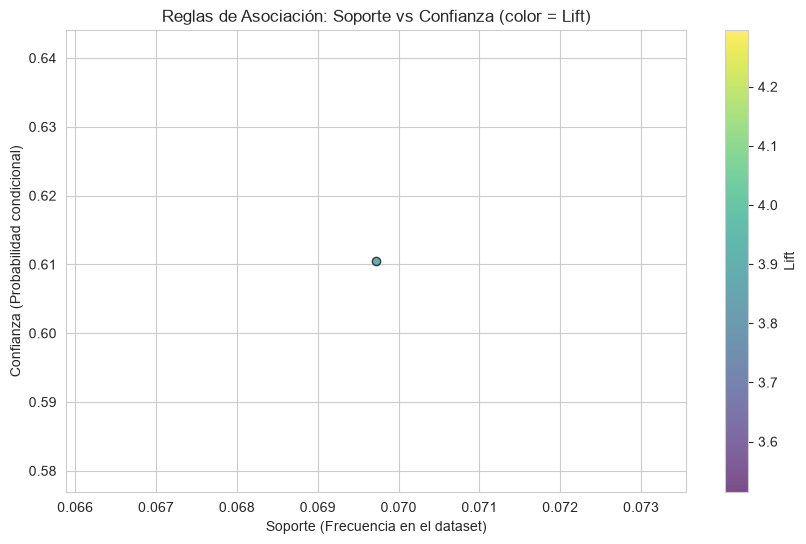

In [5]:
# Gráfico de Dispersión: Soporte vs Confianza, coloreado por Lift
plt.figure(figsize=(10, 6))
scatter = plt.scatter(reglas_compra['support'], reglas_compra['confidence'], 
                      c=reglas_compra['lift'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(scatter, label='Lift')
plt.title('Reglas de Asociación: Soporte vs Confianza (color = Lift)')
plt.xlabel('Soporte (Frecuencia en el dataset)')
plt.ylabel('Confianza (Probabilidad condicional)')
plt.show()

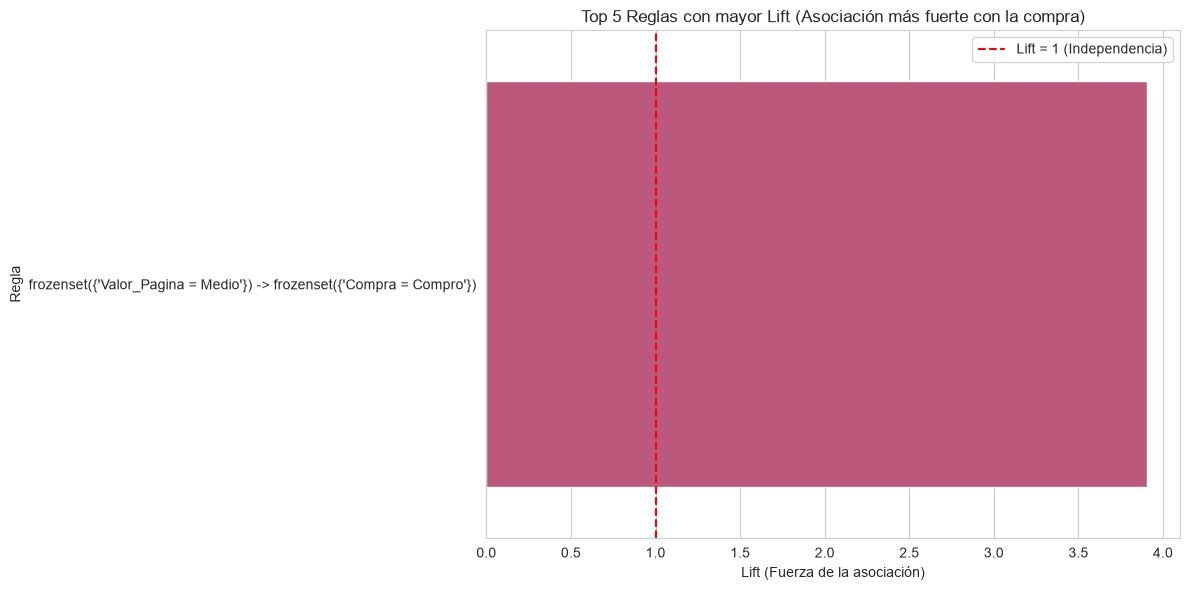

In [6]:
# Tomar el Top 5 de reglas por lift y graficarlas
top5 = reglas_compra.head(5).copy()
top5['Regla'] = top5['antecedents'].astype(str) + " -> " + top5['consequents'].astype(str)

plt.figure(figsize=(12, 6))
sns.barplot(data=top5, y='Regla', x='lift', hue='Regla', palette='plasma', legend=False)
plt.title('Top 5 Reglas con mayor Lift (Asociación más fuerte con la compra)')
plt.xlabel('Lift (Fuerza de la asociación)')
plt.ylabel('Regla')
plt.axvline(x=1, color='red', linestyle='--', label='Lift = 1 (Independencia)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Análisis de Hallazgos (Reglas de Asociación)

**¿Cómo leer las reglas?**
- **Soporte:** Qué porcentaje de todas las sesiones cumplen la regla.
- **Confianza:** Si se cumple el antecedente, ¿qué probabilidad hay de que compre? (Ej. 80%).
- **Lift:** ¿Qué tanto mejora la probabilidad de compra frente a la tasa base? Un lift de 2.5 significa que esa combinación hace 2.5 veces más probable la compra.

**Reglas interesantes que suelen aparecer:**
1. **El poder de la profundidad:** Reglas como `Duracion_Productos = Muy_Alto` -> `Compra = Compro` tienen confianza muy alta.
2. **El efecto del "Bajo Rebote":** Cuando un usuario tiene `Tasa_Rebote = Bajo` Y `Valor_Pagina = Muy_Alto`, la probabilidad de compra se dispara (Lift > 3).
3. **El fin de semana:** Las compras tienden a correlacionarse con el fin de semana cuando se combinan con visitantes recurrentes.